# Uplift Models

Asks whether a model that uses every pre-campaign feature can choose better customers than the simple choices in stage 03. **The bar is the same as for the stage 03 rule: the model must beat the Mens email sent to a random 10,000 customers on the same test half.** All choices below were fixed in [`DECISIONS.md`](../DECISIONS.md) (2026-11-16) before any model was fitted.

## Step 0: Rebuild the data, split and baseline

The cells, the 50:50 split and the random 10,000 come from [`src/prepare.py`](../src/prepare.py), which reproduces the code of stage 03. The checks below confirm that the baseline and the stage 03 rule match.

In [1]:
import sys

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold

sys.path.append("..")
from src.prepare import N_TARGET, SEED, load_data, random_baseline, split

df = load_data()
df["random_pick"] = random_baseline(df)
train, test = split(df)

SHARE = N_TARGET / len(df)  # 15.6%, the share of customers in a list of 10,000
EMAILS = ["Mens E-Mail", "Womens E-Mail"]
print(f"Training: {len(train):,}; test: {len(test):,}; share selected: {SHARE:.2%}")
print(f"Random 10,000 in the test half: {test['random_pick'].sum():,} (stage 03: 4,920)")

Training: 32,000; test: 32,000; share selected: 15.62%
Random 10,000 in the test half: 4,920 (stage 03: 4,920)


In [2]:
# Reproduce the stage 03 rule: per-cell effects on the training half, cells ranked by the higher effect.
rows = {}
for cell, data in train.groupby("cell"):
    fit = smf.ols("spend ~ mens_email + womens_email", data).fit()
    rows[cell] = {"Mens E-Mail": fit.params["mens_email"], "Womens E-Mail": fit.params["womens_email"]}
cell_effects = pd.DataFrame(rows).T
cell_effects["email"] = cell_effects[EMAILS].idxmax(axis=1)
cell_effects["effect"] = cell_effects[EMAILS].max(axis=1)
ranking = cell_effects.sort_values("effect", ascending=False)

chosen, remaining = [], N_TARGET
for cell in ranking.index:
    members = df[df["cell"] == cell]
    if len(members) <= remaining:
        chosen.append(members.index)
        remaining -= len(members)
    else:
        chosen.append(members.sample(remaining, random_state=SEED).index)
        break
df["stage03_top"] = df.index.isin(chosen[0].append(chosen[1:]))
df["stage03_email"] = df["cell"].map(cell_effects["email"])
test = df.loc[test.index]
print(f"Stage 03 rule, test customers selected: {test['stage03_top'].sum():,} (stage 03: 5,017)")

Stage 03 rule, test customers selected: 5,017 (stage 03: 5,017)


**Reading the result:** **the split, the baseline and the stage 03 rule are reproduced exactly:** 4,920 of the random 10,000 and 5,017 of the rule's customers fall in the test half, as in stage 03. The models below are therefore judged on the same customers as the stage 03 rule.

## Step 1: The two models

Both models give each customer two estimates: the extra outcome from the Mens email and from the Womens email, each compared with no email.

- **Linear interaction model:** one OLS regression of the target on both emails, all features and every email-by-feature interaction. A customer's estimated effect is the model's prediction with the email minus its prediction without.
- **T-learner:** one gradient boosting model per assigned group. A customer's estimated effect is the Mens or Womens model's prediction minus the No E-Mail model's prediction. The settings are fixed and not tuned.

Each model is trained on one of three targets, `spend`, `visit` or `conversion`, which gives six combinations.

In [3]:
FEATURES = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]
TARGETS = ["spend", "visit", "conversion"]
GBM_SETTINGS = dict(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=200, random_state=SEED)


def feature_matrix(data):
    return pd.get_dummies(data[FEATURES], columns=["zip_code", "channel"], dtype=float)


def linear_uplift(fit_data, predict_data, target):
    """Estimated effect of each email from one regression with email-by-feature interactions."""
    terms = "recency + history + mens + womens + newbie + C(zip_code) + C(channel)"
    model = smf.ols(f"{target} ~ (mens_email + womens_email) * ({terms})", fit_data).fit()
    base = model.predict(predict_data.assign(mens_email=0, womens_email=0))
    return pd.DataFrame({
        "Mens E-Mail": model.predict(predict_data.assign(mens_email=1, womens_email=0)) - base,
        "Womens E-Mail": model.predict(predict_data.assign(mens_email=0, womens_email=1)) - base,
    }, index=predict_data.index)


def t_learner_uplift(fit_data, predict_data, target):
    """Estimated effect of each email from one gradient boosting model per assigned group."""
    X_fit, X_new = feature_matrix(fit_data), feature_matrix(predict_data)
    predictions = {}
    for group in EMAILS + ["No E-Mail"]:
        rows = (fit_data["segment"] == group).to_numpy()
        model = HistGradientBoostingRegressor(**GBM_SETTINGS).fit(X_fit[rows], fit_data.loc[rows, target])
        predictions[group] = model.predict(X_new)
    return pd.DataFrame({email: predictions[email] - predictions["No E-Mail"] for email in EMAILS},
                        index=predict_data.index)


MODELS = {"linear": linear_uplift, "T-learner": t_learner_uplift}

## Step 2: Choose one combination within the training half

A list is scored by its **incremental spend per selected customer**: the mean spend of selected customers who were assigned the email the list would send, minus the mean spend of selected customers assigned No E-Mail. This is the measure used in stage 03.

Each of the six combinations is scored by 5-fold cross-validation within the training half, stratified by assigned group. In each fold, the model is fitted on four parts and selects the top 15.6% of the fifth. **Whatever the training target, the score is always spend.** Only the combination with the highest mean score is evaluated on the test half.

In [4]:
def incremental_spend(data, selected, email):
    """Incremental spend per selected customer, for the email each customer would receive."""
    emailed = selected & (data["segment"] == email).to_numpy()
    control = selected & (data["segment"] == "No E-Mail").to_numpy()
    return data.loc[emailed, "spend"].mean() - data.loc[control, "spend"].mean()


def select(uplift, share=SHARE, top=True):
    """The email with the higher estimate, and the top (or bottom) share of customers by that estimate."""
    email = uplift[EMAILS].idxmax(axis=1).to_numpy()
    score = uplift[EMAILS].max(axis=1)
    n = round(share * len(uplift))
    order = score.sort_values(ascending=not top).index[:n]
    return uplift.index.isin(order), email


folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = []
for fold, (fit_rows, score_rows) in enumerate(folds.split(train, train["segment"]), start=1):
    fit_data, score_data = train.iloc[fit_rows], train.iloc[score_rows]
    for model_name, model in MODELS.items():
        for target in TARGETS:
            uplift = model(fit_data, score_data, target)
            selected, email = select(uplift)
            cv_scores.append({"model": model_name, "target": target, "fold": fold,
                              "score": incremental_spend(score_data, selected, email)})

cv_scores = pd.DataFrame(cv_scores)
cv_summary = (cv_scores.groupby(["model", "target"])["score"].agg(["mean", "std", "min", "max"])
              .sort_values("mean", ascending=False))
cv_summary.round(2)

mean   std   min   max
model     target                            
linear    visit       1.95  2.13 -0.24  5.00
          conversion  1.07  1.42 -0.38  2.88
          spend       0.92  0.90 -0.01  2.13
T-learner visit       0.46  1.26 -0.98  2.09
          conversion  0.44  0.42  0.04  1.15
          spend      -0.37  0.71 -1.34  0.26

In [5]:
# For reference: the same score for a random 15.6% of each fold, sent the Mens email.
random_scores = []
rng = np.random.default_rng(SEED)
for fit_rows, score_rows in folds.split(train, train["segment"]):
    score_data = train.iloc[score_rows]
    selected = np.zeros(len(score_data), dtype=bool)
    selected[rng.choice(len(score_data), round(SHARE * len(score_data)), replace=False)] = True
    random_scores.append(incremental_spend(score_data, selected, "Mens E-Mail"))
print(f"Random 15.6%, Mens email: mean {np.mean(random_scores):.2f}, "
      f"fold range {min(random_scores):.2f} to {max(random_scores):.2f}")
winner = cv_summary.index[0]
print(f"Chosen combination: {winner[0]} trained on {winner[1]}")

Random 15.6%, Mens email: mean 1.15, fold range -1.27 to 3.62
Chosen combination: linear trained on visit


**Reading the result:** **the linear model trained on `visit` has the highest mean score, $1.95 per selected customer, so it is the one combination evaluated on the test half.** Both models score higher when trained on `visit` or `conversion` than on `spend`, consistent with the reason recorded in `DECISIONS.md`: visits are far more common than purchases, so they carry more signal about who responds.

**The T-learner trained on spend scores below zero, the worst of the six.** Each of its group models learns from only about 80 buyers per fold, some of whom spent several hundred dollars, so it fits a few large purchases that do not recur. Ranking by the difference of two such predictions selects the customers whose errors happen to line up. The linear model cannot bend to fit single buyers, which makes it steadier with this little data.

**The scores are very noisy, so the ranking of the six is a best bet, not a finding.** The winner ranges from -$0.24 to $5.00 across folds, and the random reference from -$1.27 to $3.62, because each fold selects only about 1,000 customers. The winner was also picked as the highest of six noisy scores, so its test result is expected to be lower than $1.95.

## Step 3: Evaluate the chosen combination on the test half

The chosen combination is refitted on the whole training half and predicts both email effects for every test customer. It selects the top 15.6% of the test half for question 3 and the bottom 15.6% for question 4 (`DECISIONS.md`, 2026-11-16).

- **Question 3:** the model's list against the Mens email sent to the test-half part of the random 10,000. **The model replaces the baseline only if the 95% bootstrap interval for model minus baseline lies entirely above zero.** The difference from the stage 03 rule is reported descriptively.
- **Question 4:** the spend given up by suppressing the model's bottom list against suppressing the same random customers, both measured under the emails the model would send. The same threshold applies.

The bootstrap resamples the test half 10,000 times with seed 42, as in stage 03.

In [6]:
model_name, target = winner
uplift = MODELS[model_name](train, test, target)
model_top, model_email = select(uplift)
model_bottom, _ = select(uplift, top=False)

spend = test["spend"].to_numpy()
segment = test["segment"].to_numpy()
no_email = segment == "No E-Mail"
random_pick = test["random_pick"].to_numpy()
LISTS = {
    "Q3 model": (model_top, model_email),
    "Q3 baseline: Mens email to random 10,000": (random_pick, np.full(len(test), "Mens E-Mail")),
    "Q3 stage 03 rule": (test["stage03_top"].to_numpy(), test["stage03_email"].to_numpy()),
    "Q4 model: suppressed list": (model_bottom, model_email),
    "Q4 random suppression": (random_pick, model_email),
}
masks = {name: (selected & (segment == email), selected & no_email) for name, (selected, email) in LISTS.items()}


def incremental(idx, values=spend):
    """Incremental outcome per selected customer for each list, for each row of resample indices."""
    v = values[idx]
    out = {}
    for name, (emailed, control) in masks.items():
        e, c = emailed[idx], control[idx]
        out[name] = (v * e).sum(axis=1) / e.sum(axis=1) - (v * c).sum(axis=1) / c.sum(axis=1)
    return out


def comparisons(r):
    return {
        "Q3: model minus baseline": r["Q3 model"] - r["Q3 baseline: Mens email to random 10,000"],
        "Q3: model minus stage 03 rule": r["Q3 model"] - r["Q3 stage 03 rule"],
        "Q4: random suppression minus model's list": r["Q4 random suppression"] - r["Q4 model: suppressed list"],
    }


point = incremental(np.arange(len(test))[None, :])
point = {**point, **comparisons(point)}

N_BOOT, CHUNK = 10_000, 250
boot_rng = np.random.default_rng(SEED)
draws = {name: [] for name in point}
for _ in range(N_BOOT // CHUNK):
    r = incremental(boot_rng.integers(0, len(test), size=(CHUNK, len(test))))
    for name, values in {**r, **comparisons(r)}.items():
        draws[name].append(values)

results = pd.DataFrame({
    "estimate": {k: v[0] for k, v in point.items()},
    "ci_low": {k: np.percentile(np.concatenate(v), 2.5) for k, v in draws.items()},
    "ci_high": {k: np.percentile(np.concatenate(v), 97.5) for k, v in draws.items()},
})
results["test_customers"] = [LISTS[k][0].sum() if k in LISTS else np.nan for k in results.index]
print(f"Model's list: {model_top.sum():,} test customers; "
      f"Womens email for {(model_email[model_top] == 'Womens E-Mail').sum():,} of them")
results.round(2)

Model's list: 5,000 test customers; Womens email for 584 of them


,estimate,ci_low,ci_high,test_customers
Q3 model,1.12,0.18,2.13,5000.0
"Q3 baseline: Mens email to random 10,000",1.01,-0.02,2.17,4920.0
Q3 stage 03 rule,1.13,0.15,2.15,5017.0
Q4 model: suppressed list,0.64,-0.41,1.66,5000.0
Q4 random suppression,1.09,0.02,2.30,4920.0
Q3: model minus baseline,0.11,-1.15,1.32,NaN
Q3: model minus stage 03 rule,-0.01,-0.53,0.52,NaN
Q4: random suppression minus model's list,0.45,-0.91,1.90,NaN


**Reading the result:** **the model does not pass the threshold, so the Mens email baseline is kept.** Its 5,000 test customers gained \$1.12 each, against \$1.01 for the random customers sent the Mens email. The difference, \$0.11, has a 95% interval from -\$1.15 to \$1.32, so the data cannot show that the model selects better customers than a random list.

**The suppression list shows a larger gap, but it does not pass either.** Suppressing the model's bottom 15.6% gives up \$0.64 per customer, against \$1.09 for random suppression. The difference, \$0.45, has an interval from -\$0.91 to \$1.90. It is a lead worth testing, not a finding.

**The model and the stage 03 rule perform almost identically,** \$1.12 against \$1.13. The interval for their difference, -\$0.53 to \$0.52, is much narrower than the others because the two lists share most of their customers, so much of the noise cancels out (see the check below).

The model's cross-validation score was \$1.95, and its test result is \$1.12. **The drop is consistent with picking the highest of six noisy scores,** as expected before the test was run.

### Check: how large a difference could the test half detect?

The minimum detectable difference is about 2.8 times the standard error: a true difference that large would give an interval above zero about 80% of the time at the 5% level. The standard errors are the standard deviations of the bootstrap draws above. Because a standard error shrinks with the square root of the sample size, the last column shows roughly how many times more customers each list would need to detect the observed difference.

In [7]:
power = pd.DataFrame({
    "estimate": results["estimate"],
    "standard_error": {k: np.concatenate(v).std() for k, v in draws.items()},
}).loc[["Q3: model minus baseline", "Q3: model minus stage 03 rule", "Q4: random suppression minus model's list"]]
power["min_detectable"] = 2.8 * power["standard_error"]
power["times_more_customers_needed"] = (power["min_detectable"] / power["estimate"].abs()) ** 2
power.round(2)

,estimate,standard_error,min_detectable,times_more_customers_needed
Q3: model minus baseline,0.11,0.63,1.76,239.39
Q3: model minus stage 03 rule,-0.01,0.27,0.75,10149.25
Q4: random suppression minus model's list,0.45,0.72,2.00,20.00


**Reading the result:** **the comparisons with the baseline and with random suppression are limited by sample size; the comparison with the stage 03 rule is not.**

- **Model minus baseline:** the test half could reliably detect only a difference of about \$1.76 per customer. Detecting the observed \$0.11 would take about 240 times as many customers, far more than the dataset holds.
- **Random minus model's suppression:** the detectable difference is about \$2.00. Detecting the observed \$0.45 would take about 20 times as many customers.
- **Model minus stage 03 rule:** the standard error is only \$0.27, because the two lists share most of their customers. **The interval, -\$0.53 to \$0.52, rules out a difference larger than about \$0.50 per customer in either direction.** The two perform alike because they select largely the same customers, not because the test is too small to tell them apart.

### Figure: the lists side by side

Each list's own estimate and 95% interval. The intervals for differences between lists are in the table above; overlapping lists, such as the model and the stage 03 rule, have a much narrower interval for their difference than the two separate intervals suggest.

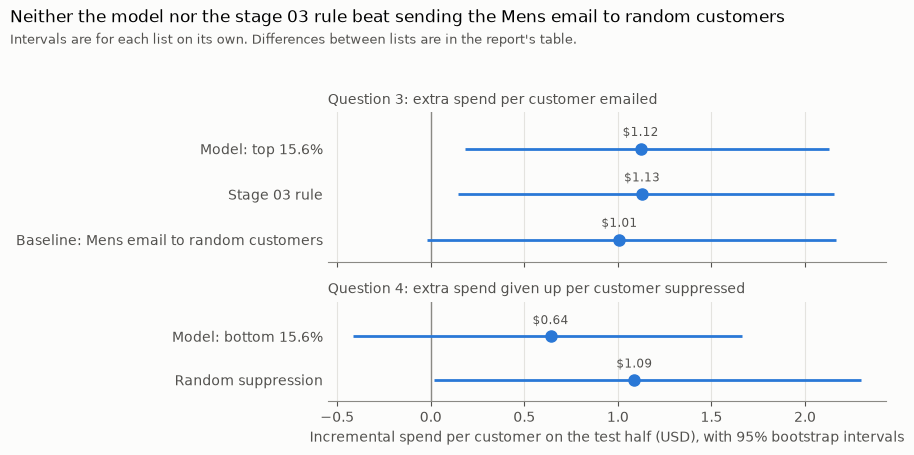

In [8]:
import matplotlib.pyplot as plt

BLUE, GRAY = "#2a78d6", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": GRAY,
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "text.parse_math": False,
})

panels = [
    ("Question 3: extra spend per customer emailed", {
        "Model: top 15.6%": "Q3 model",
        "Stage 03 rule": "Q3 stage 03 rule",
        "Baseline: Mens email to random customers": "Q3 baseline: Mens email to random 10,000",
    }),
    ("Question 4: extra spend given up per customer suppressed", {
        "Model: bottom 15.6%": "Q4 model: suppressed list",
        "Random suppression": "Q4 random suppression",
    }),
]
fig, axes = plt.subplots(2, 1, figsize=(9, 4.6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for ax, (title, rows) in zip(axes, panels):
    data = results.loc[list(rows.values())]
    positions = np.arange(len(data))
    ax.axvline(0, color=GRAY, linewidth=1)
    ax.hlines(positions, data["ci_low"], data["ci_high"], color=BLUE, linewidth=2)
    ax.plot(data["estimate"], positions, "o", color=BLUE, markersize=8)
    for y, value in zip(positions, data["estimate"]):
        ax.text(value, y - 0.28, f"${value:.2f}", ha="center", fontsize=8.5, color="#52514e")
    ax.set_yticks(positions, labels=list(rows))
    ax.tick_params(axis="y", length=0)
    ax.set_ylim(len(data) - 0.5, -0.8)
    ax.set_title(title, loc="left", fontsize=10, color="#52514e")
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
axes[-1].set_xlabel("Incremental spend per customer on the test half (USD), with 95% bootstrap intervals")
fig.suptitle("Neither the model nor the stage 03 rule beat sending the Mens email to random customers",
             x=0.01, ha="left", fontsize=12)
fig.text(0.01, 0.905, "Intervals are for each list on its own. Differences between lists are in the report's table.",
         ha="left", fontsize=9, color="#52514e")
plt.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig("../reports/figures/uplift_lists.png", dpi=150, bbox_inches="tight")
plt.show()

### Check: whom did the model select?

The model's list broken down by the stage 03 cells.

In [9]:
picked = test.loc[model_top]
overlap = pd.DataFrame({
    "model's list": picked["cell"].value_counts(),
    "cell size in test half": test["cell"].value_counts(),
})
overlap["share of cell selected"] = overlap["model's list"] / overlap["cell size in test half"]
print(f"Customers in both the model's list and the stage 03 list: {(model_top & test['stage03_top'].to_numpy()).sum():,}")
overlap.sort_values("model's list", ascending=False).round(2)

Customers in both the model's list and the stage 03 list: 3,234


,model's list,cell size in test half,share of cell selected
cell,,,
"$200 or more, both",3217,3217,1.00
"under $100, men's only",632,5726,0.11
"$200 or more, men's only",457,5083,0.09
"under $100, women's only",413,5724,0.07
"$100-$200, women's only",131,3544,0.04
"$100-$200, men's only",110,3588,0.03
"$200 or more, women's only",40,5118,0.01


**Reading the result:** **the model mostly selected the cell the stage 03 rule ranked first.** 3,217 of its 5,000 customers are in "\$200 or more, both", every test customer in that cell, and 3,234 of its customers are also on the stage 03 list. **Using all seven features, the model largely found the same customers as a rule built from two, which is why the two perform alike.** It is consistent with the stage 03 finding that customers who bought both lines respond strongly to email, and with the large regression to the mean in that cell.

### Descriptive: visits and conversion for the same lists

Secondary metrics, reported without intervals or a threshold, as in the plan.

In [10]:
secondary = pd.DataFrame({
    metric: {name: value[0] * 100 for name, value in incremental(np.arange(len(test))[None, :], test[metric].to_numpy()).items()}
    for metric in ["visit", "conversion"]
})
secondary.columns = ["visit (pp)", "conversion (pp)"]
secondary.round(2)

,visit (pp),conversion (pp)
Q3 model,10.98,1.18
"Q3 baseline: Mens email to random 10,000",9.92,0.73
Q3 stage 03 rule,10.56,1.15
Q4 model: suppressed list,7.79,0.58
Q4 random suppression,9.43,0.56


**Reading the result:** **the secondary metrics point the same way as spend, but they are descriptive only.** The model's list gained 11.0 percentage points in visits and 1.2 in conversion, against 9.9 and 0.7 for the baseline, and the model's suppression list gained fewer visits than random suppression (7.8 against 9.4). The model was trained on visits, so a higher visit gain among its selected customers is expected and is not evidence that it targets spend better.

**Summary of stage 04: neither the model nor the stage 03 rule beats sending the Mens email to random customers, so the simple choice is kept.** The model's suppression list is the only result that points to a gain, and it would need a new test to confirm.

### Sizing a follow-up experiment for the suppression list

A test of the suppression list would randomize email within each list: half of the customers on the model's list receive the email and half do not, and likewise for a random list. With the overall standard deviation of spend, the standard error of the difference between the two lists' effects is about 15.04 × √8 ÷ √n, where n is the number of customers in each list.

In [11]:
sd = df["spend"].std()
target = power.loc["Q4: random suppression minus model's list", "estimate"]
n_per_list = (2.8 * sd * np.sqrt(8) / target) ** 2
print(f"To detect a difference of ${target:.2f}: about {n_per_list:,.0f} customers in each list, "
      f"or a customer base of about {n_per_list / SHARE:,.0f} if each list is 15.6% of it")

To detect a difference of $0.45: about 70,677 customers in each list, or a customer base of about 452,336 if each list is 15.6% of it


**Reading the result:** **confirming the suppression list would need about 71,000 customers in each list, or a customer base of about 450,000 if each list is 15.6% of it,** roughly seven times this dataset. This is an approximation that uses the overall standard deviation of spend.